In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt


def read_spectra(file_path: str) -> tuple[np.ndarray, np.ndarray]:
    """
    Reads spectral data from a file and returns the wavelengths and intensities.

    Parameters:
    file_path (str): The path to the spectral data file.

    Returns:
    tuple: A tuple containing two numpy arrays: (wavelengths, intensities).
    """
    with open(file_path, 'r') as f:
        lines = f.readlines()
    while lines[0].strip('\n') != ">>>>>Begin Spectral Data<<<<<":
        lines.pop(0)
    lines.pop(0)  # Remove the ">>>>>Begin Spectral Data<<<<<
    wavelengths = []
    intensities = []
    for line in lines:
        parts = line.split()
        wavelengths.append(float(parts[0]))
        intensities.append(float(parts[1]))
    return np.array(wavelengths), np.array(intensities)

In [2]:
bg_dir = "assets/data/Background"
ref_dir = "assets/data/Reference"
sample_dir = "assets/data/Sample"

/var/folders/44/62vjt8dx0sd5w6cnwjv2k5gc0000gn/T/ipykernel_58653/3668520478.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


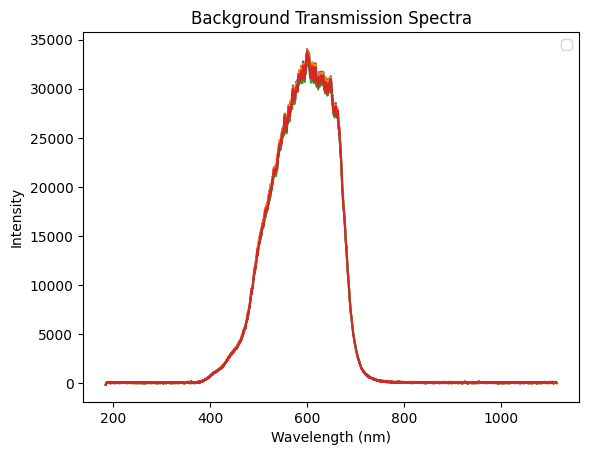

In [3]:
fig, ax = plt.subplots()
bg_wavelengths = []
bg_intensities = []
for file in os.listdir(bg_dir):
    if file.endswith(".txt"):
        file_path = os.path.join(bg_dir, file)
        wavelengths, intensities = read_spectra(file_path)
        bg_wavelengths.append(wavelengths)
        bg_intensities.append(intensities)
        ax.plot(wavelengths, intensities)
ax.set_title("Background Transmission Spectra")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Intensity")

# Use average of background spectra as the background spectrum
bg_wavelengths = np.array(bg_wavelengths)
bg_intensities = np.array(bg_intensities)
avg_bg_wavelengths = np.mean(bg_wavelengths, axis=0)
avg_bg_intensities = np.mean(bg_intensities, axis=0)
# ax.plot(avg_bg_wavelengths, avg_bg_intensities, label="Average Background", color="black", linewidth=2, alpha=0.7)
ax.legend()
plt.savefig(os.path.join('assets/figure', 'background_spectra.png'), dpi=300)

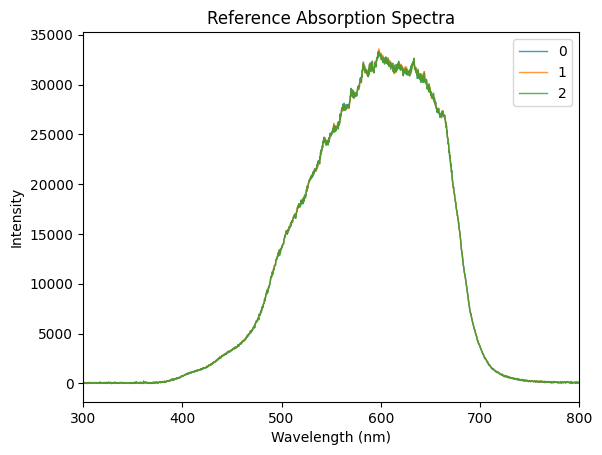

In [4]:
fig, ax = plt.subplots()
for i, file in enumerate(os.listdir(ref_dir)):
    if file.endswith(".txt"):
        file_path = os.path.join(ref_dir, file)
        wavelengths, intensities = read_spectra(file_path)
        ax.plot(wavelengths, intensities, linewidth=1, alpha=0.8, label=i)
ax.set_title("Reference Absorption Spectra")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Intensity")
ax.set_xlim(300, 800)
ax.legend()

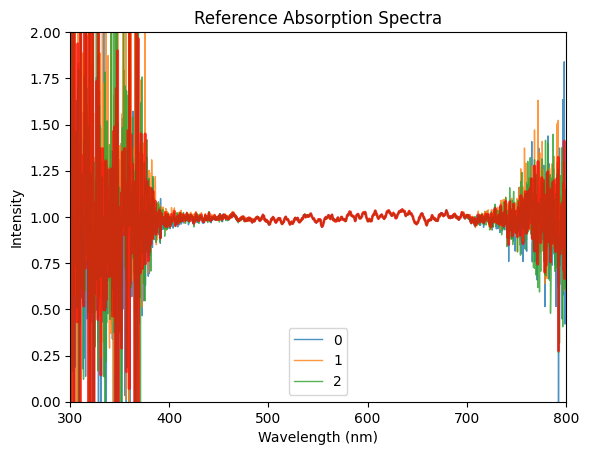

In [5]:
fig, ax = plt.subplots()
ref_wavelengths = []
ref_intensities = []
for i, file in enumerate(os.listdir(ref_dir)):
    if file.endswith(".txt"):
        file_path = os.path.join(ref_dir, file)
        wavelengths, intensities = read_spectra(file_path)
        ax.plot(wavelengths, intensities / avg_bg_intensities, linewidth=1, alpha=0.8, label=i)
        ref_wavelengths.append(wavelengths)
        ref_intensities.append(intensities / avg_bg_intensities)
ax.set_title("Reference Absorption Spectra")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Intensity")
ax.set_xlim(300, 800)
avg_ref_wavelengths = np.mean(ref_wavelengths, axis=0)
avg_ref_intensities = np.mean(ref_intensities, axis=0)
ax.legend()
ax.set_ylim(0, 2)
ax.plot(avg_ref_wavelengths, avg_ref_intensities, label="Average Reference", color="red", linewidth=2, alpha=0.7)
plt.savefig(os.path.join('assets/figure', 'reference_spectra.png'), dpi=300)

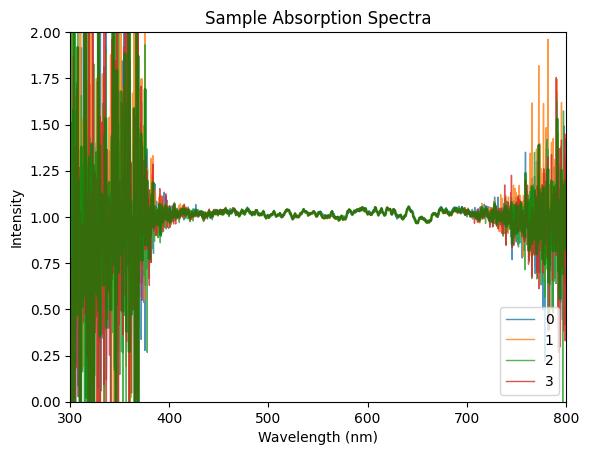

In [6]:
fig, ax = plt.subplots()
sample_wavelengths = []
sample_intensities = []
for i, file in enumerate(os.listdir(sample_dir)):
    if file.endswith(".txt"):
        file_path = os.path.join(sample_dir, file)
        wavelengths, intensities = read_spectra(file_path)
        ax.plot(wavelengths, intensities / avg_bg_intensities, linewidth=1, alpha=0.8, label=i)
        sample_wavelengths.append(wavelengths)
        sample_intensities.append(intensities / avg_bg_intensities)
ax.set_title("Sample Absorption Spectra")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Intensity")
ax.set_xlim(300, 800)
ax.legend(loc="lower right")
ax.set_ylim(0, 2)
avg_sample_wavelengths = np.mean(sample_wavelengths, axis=0)
avg_sample_intensities = np.mean(sample_intensities, axis=0)
ax.plot(avg_sample_wavelengths, avg_sample_intensities, label="Average Sample", color="green", linewidth=2, alpha=0.7)
plt.savefig(os.path.join('assets/figure', 'sample_spectra.png'), dpi=300)

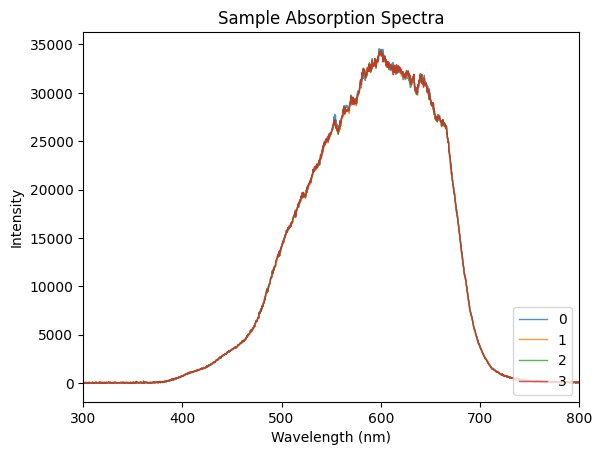

In [7]:
fig, ax = plt.subplots()
for i, file in enumerate(os.listdir(sample_dir)):
    if file.endswith(".txt"):
        file_path = os.path.join(sample_dir, file)
        wavelengths, intensities = read_spectra(file_path)
        ax.plot(wavelengths, intensities, linewidth=1, alpha=0.8, label=i)
ax.set_title("Sample Absorption Spectra")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Intensity")
ax.set_xlim(300, 800)
ax.legend(loc="lower right")

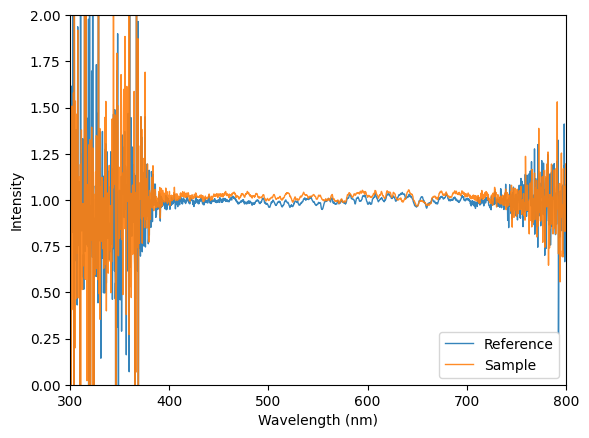

In [8]:
fig, ax = plt.subplots()
ax.plot(avg_ref_wavelengths, avg_ref_intensities, label="Reference", color="tab:blue", linewidth=1, alpha=0.9)
ax.plot(avg_sample_wavelengths, avg_sample_intensities, label="Sample", color="tab:orange", linewidth=1, alpha=0.9)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Intensity")
ax.legend(loc="lower right")
ax.set_xlim(300, 800)
ax.set_ylim(0, 2)
plt.savefig(os.path.join('assets/figure', 'reference_sample_comparison.png'), dpi=300)

/var/folders/44/62vjt8dx0sd5w6cnwjv2k5gc0000gn/T/ipykernel_58653/3582909340.py:1: RuntimeWarning: invalid value encountered in log10
  absorp = -np.log10((avg_sample_intensities - avg_bg_intensities) / (avg_ref_intensities - avg_bg_intensities))


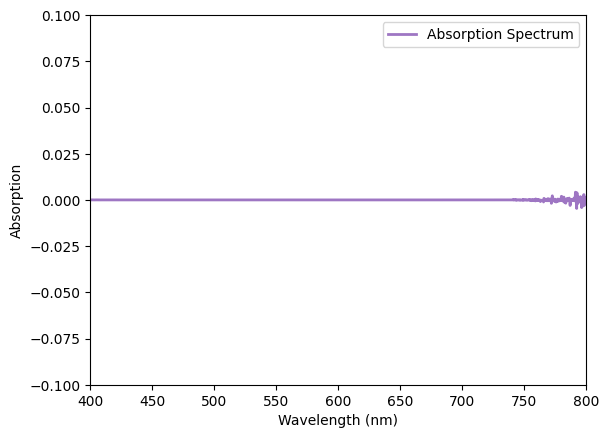

In [13]:
absorp = -np.log10((avg_sample_intensities - avg_bg_intensities) / (avg_ref_intensities - avg_bg_intensities))
fig, ax = plt.subplots()
ax.plot(avg_ref_wavelengths, absorp, label="Absorption Spectrum", color="tab:purple", linewidth=2, alpha=0.9)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Absorption")
ax.legend()
ax.set_xlim(400, 800)
ax.set_ylim(-0.1, 0.1)
fig.savefig(os.path.join('assets/figure', 'absorption_spectrum.png'), dpi=300)